In [1]:
import pandas as pd 

metadata = pd.read_csv("Pv4_samples (1).txt", sep = '\t')

metadata_df = pd.DataFrame(metadata)

In [2]:
metadata_df.shape

(1895, 15)

In [3]:
fws = pd.read_csv("Pv4_fws.txt", sep = '\t')

fws_vals = pd.DataFrame(fws)

fws_pass = fws_vals.loc[fws_vals['Fws']>=0.95]

fws_samples = list(fws_pass['Sample'])

metadata_df_fws = metadata_df.loc[metadata_df['Sample'].isin(fws_samples)]

In [4]:
metadata_df_fws.shape

(694, 15)

In [9]:
metadata_df_qc = metadata_df_fws.loc[metadata_df["QC pass"] == True]

In [10]:
metadata_df_qc.shape

(694, 15)

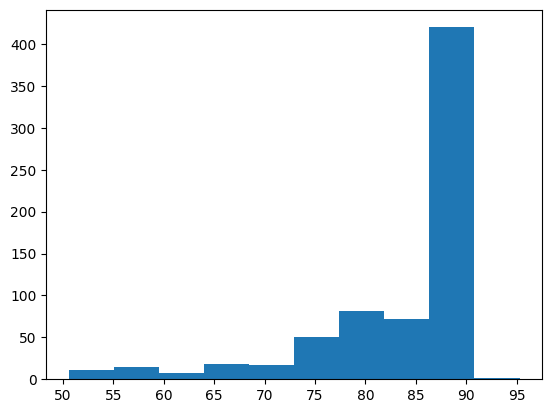

In [5]:
#Investigate distribution of percentage callable column, e
import matplotlib.pyplot as plt

plt.hist(metadata_df_qc['% callable'])

plt.xticks(range(50,100, 5))

plt.show()

In [11]:
metadata_df_per = metadata_df_qc.loc[metadata_df_qc['% callable'] >= 80]

metadata_df_per.shape

(532, 15)

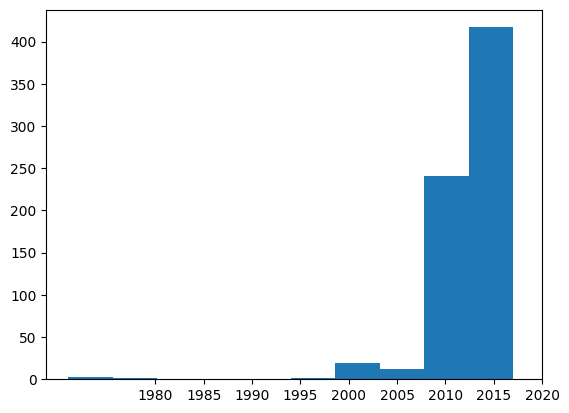

In [6]:
#Investigate distribution of Year column, try to include the most recent samples possible while maintaining sufficient numbers. 
import matplotlib.pyplot as plt

plt.hist(metadata_df_qc['Year'])

plt.xticks(range(1980,2025, 5))

plt.show()

In [12]:
metadata_df_per

metadata_df_new = metadata_df_per.loc[metadata_df_per['Year'] >= 2010]

metadata_df_new.shape

(450, 15)

In [13]:
pd.unique(metadata_df_new['Country'])

array(['Ethiopia', 'Colombia', 'Cambodia', 'Thailand', 'Indonesia',
       'Brazil', 'Sri Lanka', 'India', 'Malaysia', 'Peru', 'Vietnam',
       'Philippines', 'Afghanistan'], dtype=object)

In [16]:
SE_asia = ['Cambodia', 'Thailand', 'Indonesia', 'Vietnam', 'Philippines', 'Malaysia'] 
Asia = ['Afghanistan', 'India','Sri Lanka'] 
America = ['Brazil', 'Colombia', 'Mexico', 'Nicaragua', 'Peru', 'El Salvador'] 
Other = ['Iran','Papua New Guinea','Ethiopia']

In [18]:
#Create separate tables consisting of samples from specific continents/ subcontinents
metadata_se = metadata_df_new.loc[metadata_df_new["Country"].isin(SE_asia)]
metadata_as = metadata_df_new.loc[metadata_df_new["Country"].isin(Asia)]
metadata_am = metadata_df_new.loc[metadata_df_new["Country"].isin(America)]
metadata_ot = metadata_df_new.loc[metadata_df_new["Country"].isin(Other)]

In [25]:
sea = 90
asi = 14
ame = 36
oth = 10

In [26]:
import random
random.seed(6967)

sea_tot = list(range(0, metadata_se.shape[0]))
sea_fin = random.sample(sea_tot, sea)

asi_tot = list(range(0, metadata_as.shape[0]))
asi_fin = random.sample(asi_tot, asi)

ame_tot = list(range(0, metadata_am.shape[0]))
ame_fin = random.sample(ame_tot, ame)

oth_tot = list(range(0, metadata_ot.shape[0]))
oth_fin = random.sample(oth_tot, oth)

In [27]:
metadata_se_fin = metadata_se.iloc[sea_fin, :]
metadata_as_fin = metadata_as.iloc[asi_fin, :]
metadata_am_fin = metadata_am.iloc[ame_fin, :]
metadata_ot_fin = metadata_ot.iloc[oth_fin, :]

In [29]:
se_samples = list(metadata_se_fin['Sample'])
as_samples = list(metadata_as_fin['Sample'])
am_samples = list(metadata_am_fin['Sample'])
ot_samples = list(metadata_ot_fin['Sample'])
total_samples = se_samples + as_samples + am_samples + ot_samples

In [30]:
with open('pv_samples_tot.txt', 'w+') as f:
    
    for item in total_samples:
        f.write('%s\n' %item)

f.close()